# **TASK 2: Exploratory Data Analysis (EDA)**

# Ask meaningful questions about the dataset before analysis.

1. What is the size and structure of the dataset, and what does each variable represent?
2. Are there missing values, duplicate rows, incorrect data types, impossible values, or inconsistent calculated fields?
3. Which product lines and branches generate the highest total sales?
4. How do sales vary by month, day of the week, and time of day?
5. Which payment methods and customer types are most common?
6. Are sales amounts different between Members and Normal customers?
7. Is there evidence that average sales differ among branches?
8. Are there unusual sales values or ratings that need investigation?


# Explore the data structure, including variables and data types.

In [ ]:
from google.colab import files
uploaded = files.upload()  # Choose Sales_data.csv

import io
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)

file_name = next(iter(uploaded))
df = pd.read_csv(io.BytesIO(uploaded[file_name]))

print("Dataset loaded successfully.")
print(f"Rows: {df.shape[0]:,}")
print(f"Columns: {df.shape[1]:,}")
display(df.head())

Saving Sales_data.csv to Sales_data.csv
Dataset loaded successfully.
Rows: 1,000
Columns: 20


,Invoice ID,Branch,City,Customer type,Gender,Product line,Unit price,Quantity,Tax 5%,Sales,Date,Time,Payment,cogs,gross margin percentage,gross income,Rating,Month,Year,Day Name
0,750-67-8428,Alex,Yangon,Member,Female,Health and beauty,74.69,7,26.1415,548.9715,1/5/2019,1:08:00 PM,Ewallet,522.83,4.761905,26.1415,9.1,January,2019,Saturday
1,226-31-3081,Giza,Naypyitaw,Normal,Female,Electronic accessories,15.28,5,3.8200,80.2200,3/8/2019,10:29:00 AM,Cash,76.40,4.761905,3.8200,9.6,March,2019,Friday
2,631-41-3108,Alex,Yangon,Normal,Female,Home and lifestyle,46.33,7,16.2155,340.5255,3/3/2019,1:23:00 PM,Credit card,324.31,4.761905,16.2155,7.4,March,2019,Sunday
3,123-19-1176,Alex,Yangon,Member,Female,Health and beauty,58.22,8,23.2880,489.0480,1/27/2019,8:33:00 PM,Ewallet,465.76,4.761905,23.2880,8.4,January,2019,Sunday
4,373-73-7910,Alex,Yangon,Member,Female,Sports and travel,86.31,7,30.2085,634.3785,2/8/2019,10:37:00 AM,Ewallet,604.17,4.761905,30.2085,5.3,February,2019,Friday


In [ ]:
print("Dataset shape:", df.shape)

print("\\nColumn names:")
print(df.columns.tolist())

print("\\nData types and non-null counts:")
df.info()

print("\\nDescriptive statistics — numeric columns:")
display(df.describe().T)

print("\\nSummary of categorical columns:")
display(df.describe(include="object").T)

Dataset shape: (1000, 20)
\nColumn names:
['Invoice ID', 'Branch', 'City', 'Customer type', 'Gender', 'Product line', 'Unit price', 'Quantity', 'Tax 5%', 'Sales', 'Date', 'Time', 'Payment', 'cogs', 'gross margin percentage', 'gross income', 'Rating', 'Month', 'Year', 'Day Name']
\nData types and non-null counts:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 20 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Invoice ID               1000 non-null   object 
 1   Branch                   1000 non-null   object 
 2   City                     1000 non-null   object 
 3   Customer type            1000 non-null   object 
 4   Gender                   1000 non-null   object 
 5   Product line             1000 non-null   object 
 6   Unit price               1000 non-null   float64
 7   Quantity                 1000 non-null   int64  
 8   Tax 5%                   1000 non-n

,count,mean,std,min,25%,50%,75%,max
Unit price,1000.0,55.672130,2.649463e+01,10.080000,32.875000,55.230000,77.935000,99.960000
Quantity,1000.0,5.510000,2.923431e+00,1.000000,3.000000,5.000000,8.000000,10.000000
Tax 5%,1000.0,15.379369,1.170883e+01,0.508500,5.924875,12.088000,22.445250,49.650000
Sales,1000.0,322.966749,2.458853e+02,10.678500,124.422375,253.848000,471.350250,1042.650000
cogs,1000.0,307.587380,2.341765e+02,10.170000,118.497500,241.760000,448.905000,993.000000
gross margin percentage,1000.0,4.761905,6.131498e-14,4.761905,4.761905,4.761905,4.761905,4.761905
gross income,1000.0,15.379369,1.170883e+01,0.508500,5.924875,12.088000,22.445250,49.650000
Rating,1000.0,6.972700,1.718580e+00,4.000000,5.500000,7.000000,8.500000,10.000000
Year,1000.0,2019.000000,0.000000e+00,2019.000000,2019.000000,2019.000000,2019.000000,2019.000000


\nSummary of categorical columns:


,count,unique,top,freq
Invoice ID,1000,1000,849-09-3807,1
Branch,1000,3,Alex,340
City,1000,3,Yangon,340
Customer type,1000,2,Member,565
Gender,1000,2,Female,571
Product line,1000,6,Fashion accessories,178
Date,1000,89,2/7/2019,20
Time,1000,506,7:48:00 PM,7
Payment,1000,3,Ewallet,345
Month,1000,3,January,352


In [ ]:
print("Missing values by column:")
display(df.isna().sum().sort_values(ascending=False).to_frame("Missing count"))

print("Exact duplicate rows:", df.duplicated().sum())

if "Invoice ID" in df.columns:
    print("Duplicate Invoice IDs:", df["Invoice ID"].duplicated().sum())

print("\\nUnique values per column:")
display(df.nunique(dropna=False).to_frame("Unique values"))


Missing values by column:


,Missing count
Invoice ID,0
Branch,0
City,0
Customer type,0
Gender,0
Product line,0
Unit price,0
Quantity,0
Tax 5%,0
Sales,0


Exact duplicate rows: 0
Duplicate Invoice IDs: 0
\nUnique values per column:


,Unique values
Invoice ID,1000
Branch,3
City,3
Customer type,2
Gender,2
Product line,6
Unit price,943
Quantity,10
Tax 5%,990
Sales,990


In [ ]:
numeric_columns = [
    "Unit price", "Quantity", "Tax 5%", "Sales", "cogs",
    "gross margin percentage", "gross income", "Rating"
]
for col in numeric_columns:
    if col in df.columns:
        df[col] = pd.to_numeric(df[col], errors="coerce")

range_checks = {}
if "Unit price" in df.columns:
    range_checks["Unit price <= 0"] = int((df["Unit price"] <= 0).sum())
if "Quantity" in df.columns:
    range_checks["Quantity <= 0"] = int((df["Quantity"] <= 0).sum())
if "Sales" in df.columns:
    range_checks["Sales <= 0"] = int((df["Sales"] <= 0).sum())
if "Rating" in df.columns:
    range_checks["Rating outside 0–10"] = int(((df["Rating"] < 0) | (df["Rating"] > 10)).sum())

display(pd.Series(range_checks, name="Flagged row count").to_frame())

# Arithmetic consistency checks, allowing a small rounding tolerance.
def mismatch_count(left, right, tolerance=0.02):
    valid = left.notna() & right.notna()
    return int(((left[valid] - right[valid]).abs() > tolerance).sum())

if {"Unit price", "Quantity", "cogs"}.issubset(df.columns):
    print("Rows where Unit price × Quantity differs from cogs:",
          mismatch_count(df["Unit price"] * df["Quantity"], df["cogs"]))

if {"cogs", "Tax 5%", "Sales"}.issubset(df.columns):
    print("Rows where cogs + Tax 5% differs from Sales:",
          mismatch_count(df["cogs"] + df["Tax 5%"], df["Sales"]))

if {"Tax 5%", "gross income"}.issubset(df.columns):
    print("Rows where Tax 5% differs from gross income:",
          mismatch_count(df["Tax 5%"], df["gross income"]))

if "gross margin percentage" in df.columns:
    print("Gross margin percentage unique values:")
    print(sorted(df["gross margin percentage"].dropna().unique())[:20])


,Flagged row count
Unit price <= 0,0
Quantity <= 0,0
Sales <= 0,0
Rating outside 0–10,0


Rows where Unit price × Quantity differs from cogs: 0
Rows where cogs + Tax 5% differs from Sales: 0
Rows where Tax 5% differs from gross income: 0
Gross margin percentage unique values:
[np.float64(4.761904762)]


In [ ]:
eda = df.copy()

if "Date" in eda.columns:
    # The supplied dataset commonly uses month/day/year dates.
    eda["Date"] = pd.to_datetime(eda["Date"], format="%m/%d/%Y", errors="coerce")

if "Time" in eda.columns:
    eda["Parsed Time"] = pd.to_datetime(
        eda["Time"].astype(str), format="%I:%M:%S %p", errors="coerce"
    ).dt.time

if "Date" in eda.columns:
    eda["Month Number Derived"] = eda["Date"].dt.month
    eda["Month Derived"] = eda["Date"].dt.month_name()
    eda["Day Name Derived"] = eda["Date"].dt.day_name()
    eda["Hour"] = pd.to_datetime(
        eda["Time"].astype(str), format="%I:%M:%S %p", errors="coerce"
    ).dt.hour if "Time" in eda.columns else np.nan

print("Invalid/unparsed dates:", int(eda["Date"].isna().sum()) if "Date" in eda.columns else "No Date column")
if "Parsed Time" in eda.columns:
    print("Invalid/unparsed times:", int(eda["Parsed Time"].isna().sum()))
display(eda.head())


Invalid/unparsed dates: 0
Invalid/unparsed times: 0


,Invoice ID,Branch,City,Customer type,Gender,Product line,Unit price,Quantity,Tax 5%,Sales,Date,Time,Payment,cogs,gross margin percentage,gross income,Rating,Month,Year,Day Name,Parsed Time,Month Number Derived,Month Derived,Day Name Derived,Hour
0,750-67-8428,Alex,Yangon,Member,Female,Health and beauty,74.69,7,26.1415,548.9715,2019-01-05,1:08:00 PM,Ewallet,522.83,4.761905,26.1415,9.1,January,2019,Saturday,13:08:00,1,January,Saturday,13
1,226-31-3081,Giza,Naypyitaw,Normal,Female,Electronic accessories,15.28,5,3.8200,80.2200,2019-03-08,10:29:00 AM,Cash,76.40,4.761905,3.8200,9.6,March,2019,Friday,10:29:00,3,March,Friday,10
2,631-41-3108,Alex,Yangon,Normal,Female,Home and lifestyle,46.33,7,16.2155,340.5255,2019-03-03,1:23:00 PM,Credit card,324.31,4.761905,16.2155,7.4,March,2019,Sunday,13:23:00,3,March,Sunday,13
3,123-19-1176,Alex,Yangon,Member,Female,Health and beauty,58.22,8,23.2880,489.0480,2019-01-27,8:33:00 PM,Ewallet,465.76,4.761905,23.2880,8.4,January,2019,Sunday,20:33:00,1,January,Sunday,20
4,373-73-7910,Alex,Yangon,Member,Female,Sports and travel,86.31,7,30.2085,634.3785,2019-02-08,10:37:00 AM,Ewallet,604.17,4.761905,30.2085,5.3,February,2019,Friday,10:37:00,2,February,Friday,10


In [ ]:
def show_sum(column):
    return eda[column].sum() if column in eda.columns else np.nan

kpis = {
    "Rows / records": len(eda),
    "Unique transactions": eda["Invoice ID"].nunique() if "Invoice ID" in eda.columns else np.nan,
    "Total sales": show_sum("Sales"),
    "Total gross income": show_sum("gross income"),
    "Total quantity sold": show_sum("Quantity"),
    "Average rating": eda["Rating"].mean() if "Rating" in eda.columns else np.nan,
}
display(pd.Series(kpis, name="Value").to_frame())


,Value
Rows / records,1000.0000
Unique transactions,1000.0000
Total sales,322966.7490
Total gross income,15379.3690
Total quantity sold,5510.0000
Average rating,6.9727


# Identify trends, patterns and anomalies within the data.

,Total sales
Product line,
Food and beverages,56144.8440
Sports and travel,55122.8265
Electronic accessories,54337.5315
Fashion accessories,54305.8950
Home and lifestyle,53861.9130
Health and beauty,49193.7390


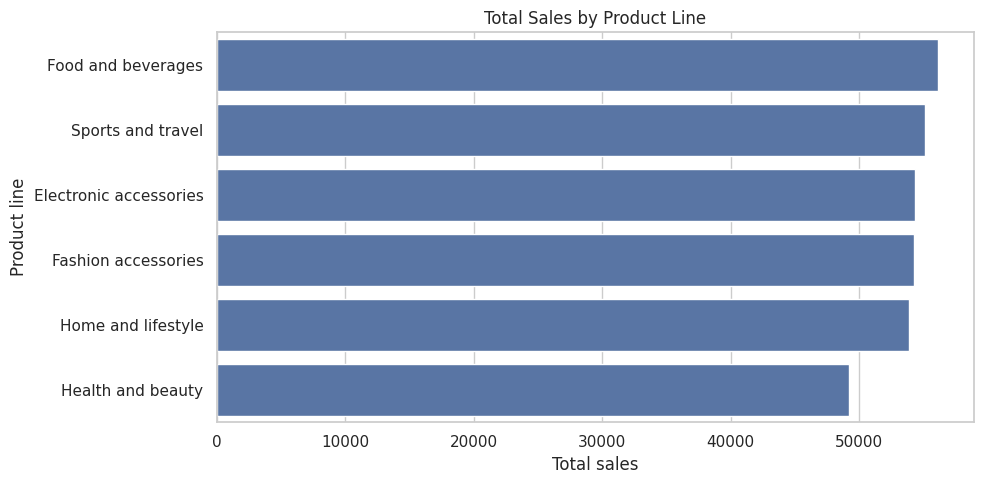

,Total sales
Branch,
Giza,110568.7065
Alex,106200.3705
Cairo,106197.6720


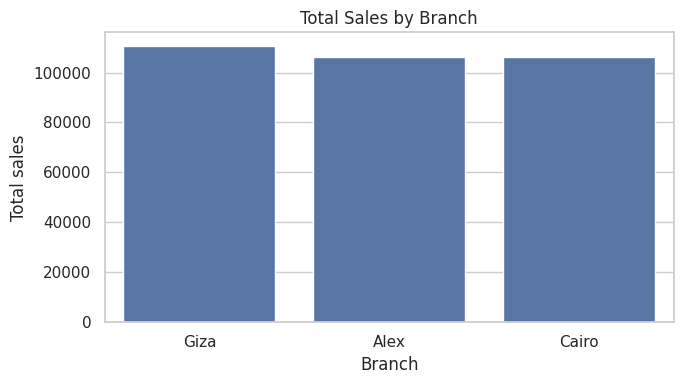

In [ ]:
if {"Product line", "Sales"}.issubset(eda.columns):
    product_sales = eda.groupby("Product line")["Sales"].sum().sort_values(ascending=False)
    display(product_sales.to_frame("Total sales"))
    plt.figure(figsize=(10, 5))
    sns.barplot(x=product_sales.values, y=product_sales.index)
    plt.title("Total Sales by Product Line")
    plt.xlabel("Total sales")
    plt.ylabel("Product line")
    plt.tight_layout()
    plt.show()

if {"Branch", "Sales"}.issubset(eda.columns):
    branch_sales = eda.groupby("Branch")["Sales"].sum().sort_values(ascending=False)
    display(branch_sales.to_frame("Total sales"))
    plt.figure(figsize=(7, 4))
    sns.barplot(x=branch_sales.index, y=branch_sales.values)
    plt.title("Total Sales by Branch")
    plt.xlabel("Branch")
    plt.ylabel("Total sales")
    plt.tight_layout()
    plt.show()


,Total sales
Date,
2019-01,116291.868
2019-02,97219.374
2019-03,109455.507


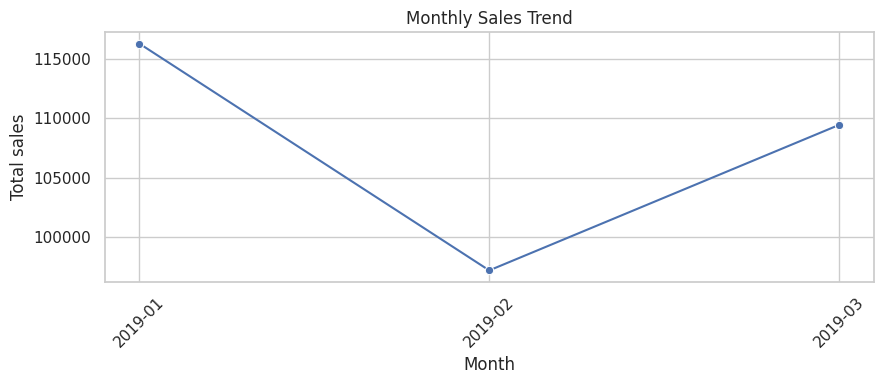

,Total sales by weekday
Day Name Derived,
Monday,37899.0780
Tuesday,51482.2455
Wednesday,43731.1350
Thursday,45349.2480
Friday,43926.3405
Saturday,56120.8095
Sunday,44457.8925


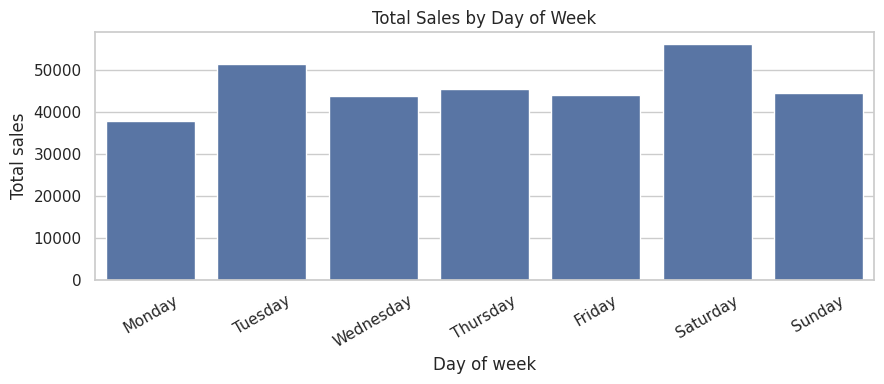

In [ ]:
if {"Date", "Sales"}.issubset(eda.columns):
    monthly_sales = (
        eda.dropna(subset=["Date"])
           .groupby(eda["Date"].dt.to_period("M"))["Sales"]
           .sum()
    )
    monthly_sales.index = monthly_sales.index.astype(str)
    display(monthly_sales.to_frame("Total sales"))
    plt.figure(figsize=(9, 4))
    sns.lineplot(x=monthly_sales.index, y=monthly_sales.values, marker="o")
    plt.title("Monthly Sales Trend")
    plt.xlabel("Month")
    plt.ylabel("Total sales")
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

if {"Day Name Derived", "Sales"}.issubset(eda.columns):
    weekday_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
    weekday_sales = eda.groupby("Day Name Derived")["Sales"].sum().reindex(weekday_order)
    display(weekday_sales.to_frame("Total sales by weekday"))
    plt.figure(figsize=(9, 4))
    sns.barplot(x=weekday_sales.index, y=weekday_sales.values)
    plt.title("Total Sales by Day of Week")
    plt.xlabel("Day of week")
    plt.ylabel("Total sales")
    plt.xticks(rotation=30)
    plt.tight_layout()
    plt.show()


Counts for Customer type:


,Count
Customer type,
Member,565
Normal,435


Counts for Gender:


,Count
Gender,
Female,571
Male,429


Counts for Payment:


,Count
Payment,
Ewallet,345
Cash,344
Credit card,311


,count,mean,median,sum
Customer type,,,,
Member,565,335.74,271.95,189694.76
Normal,435,306.37,225.79,133271.98


,Average rating
Product line,
Food and beverages,7.113218
Fashion accessories,7.029213
Health and beauty,7.003289
Electronic accessories,6.924706
Sports and travel,6.916265
Home and lifestyle,6.837500


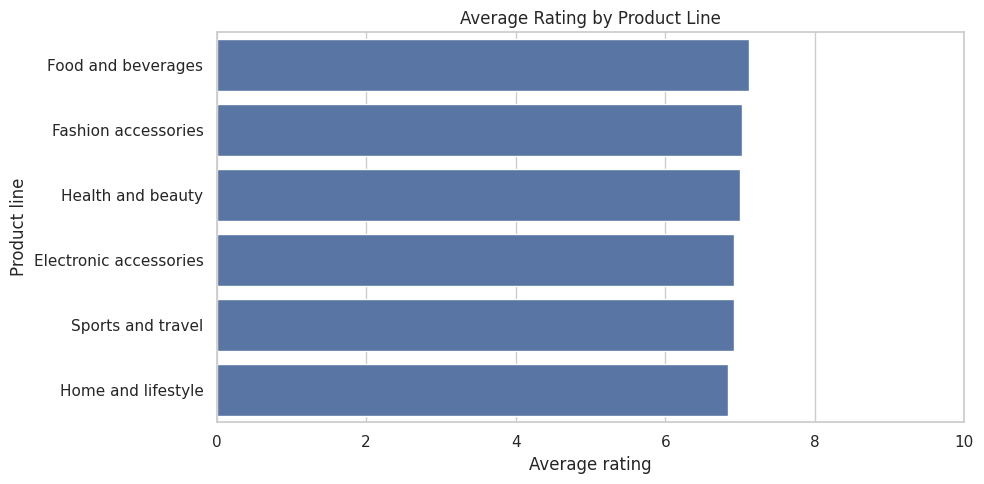

In [ ]:
for col in ["Customer type", "Gender", "Payment"]:
    if col in eda.columns:
        print(f"Counts for {col}:")
        display(eda[col].value_counts(dropna=False).to_frame("Count"))

if {"Customer type", "Sales"}.issubset(eda.columns):
    display(eda.groupby("Customer type")["Sales"].agg(["count", "mean", "median", "sum"]).round(2))

if {"Product line", "Rating"}.issubset(eda.columns):
    ratings = eda.groupby("Product line")["Rating"].mean().sort_values(ascending=False)
    display(ratings.to_frame("Average rating"))
    plt.figure(figsize=(10, 5))
    sns.barplot(x=ratings.values, y=ratings.index)
    plt.title("Average Rating by Product Line")
    plt.xlabel("Average rating")
    plt.ylabel("Product line")
    plt.xlim(0, 10)
    plt.tight_layout()
    plt.show()


# Test hypotheses and validate assumptions using statistics and visualization.

In [ ]:
from scipy import stats

alpha = 0.05

if {"Customer type", "Sales"}.issubset(eda.columns):
    group_member = eda.loc[eda["Customer type"] == "Member", "Sales"].dropna()
    group_normal = eda.loc[eda["Customer type"] == "Normal", "Sales"].dropna()

    print("Member count:", len(group_member), "| mean sales:", round(group_member.mean(), 2))
    print("Normal count:", len(group_normal), "| mean sales:", round(group_normal.mean(), 2))

    if len(group_member) >= 2 and len(group_normal) >= 2:
        t_stat, p_value = stats.ttest_ind(group_member, group_normal, equal_var=False)
        print(f"Welch t-statistic: {t_stat:.4f}")
        print(f"p-value: {p_value:.6f}")
        print("Decision:", "Reject H0 (statistically significant difference)" if p_value < alpha
              else "Do not reject H0 (insufficient evidence of a difference)")
    else:
        print("Not enough observations to run the test.")
else:
    print("Required columns are missing.")


Member count: 565 | mean sales: 335.74
Normal count: 435 | mean sales: 306.37
Welch t-statistic: 1.8862
p-value: 0.059566
Decision: Do not reject H0 (insufficient evidence of a difference)


In [ ]:
if {"Branch", "Sales"}.issubset(eda.columns):
    branch_groups = [
        group["Sales"].dropna().values
        for _, group in eda.groupby("Branch")
        if group["Sales"].notna().sum() >= 2
    ]

    print("Branch summary:")
    display(eda.groupby("Branch")["Sales"].agg(["count", "mean", "median", "std"]).round(2))

    if len(branch_groups) >= 2:
        f_stat, p_value = stats.f_oneway(*branch_groups)
        print(f"ANOVA F-statistic: {f_stat:.4f}")
        print(f"p-value: {p_value:.6f}")
        print("Decision:", "Reject H0 (at least one mean differs)" if p_value < alpha
              else "Do not reject H0 (insufficient evidence that means differ)")
    else:
        print("Not enough branch groups to run ANOVA.")
else:
    print("Required columns are missing.")


Branch summary:


,count,mean,median,std
Branch,,,,
Alex,340,312.35,240.83,231.64
Cairo,332,319.87,252.88,242.45
Giza,328,337.10,271.42,263.16


ANOVA F-statistic: 0.8846
p-value: 0.413210
Decision: Do not reject H0 (insufficient evidence that means differ)


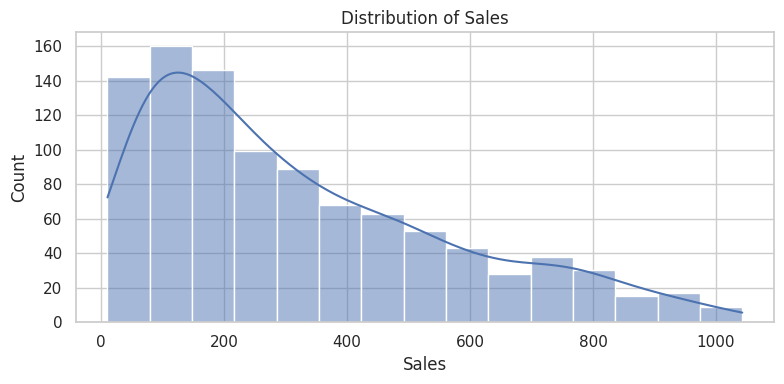

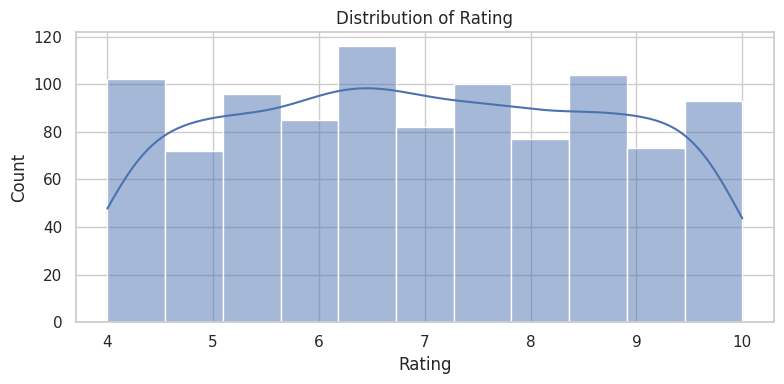

,count,mean,std
Customer type,,,
Member,565,335.74,250.42
Normal,435,306.37,239.14


,count,mean,std
Branch,,,
Alex,340,312.35,231.64
Cairo,332,319.87,242.45
Giza,328,337.10,263.16


In [ ]:
# Visualize the distribution of transaction sales and ratings.
for col in ["Sales", "Rating"]:
    if col in eda.columns:
        plt.figure(figsize=(8, 4))
        sns.histplot(eda[col].dropna(), kde=True)
        plt.title(f"Distribution of {col}")
        plt.xlabel(col)
        plt.tight_layout()
        plt.show()

# Show mean and standard deviation by customer type and branch, if available.
if {"Customer type", "Sales"}.issubset(eda.columns):
    display(eda.groupby("Customer type")["Sales"].agg(["count", "mean", "std"]).round(2))
if {"Branch", "Sales"}.issubset(eda.columns):
    display(eda.groupby("Branch")["Sales"].agg(["count", "mean", "std"]).round(2))


# Detect potential data issues or problems to address in further analysis.

Sales: 9 potential outliers out of 1000 non-missing values
  IQR lower bound=-395.969; upper bound=991.742


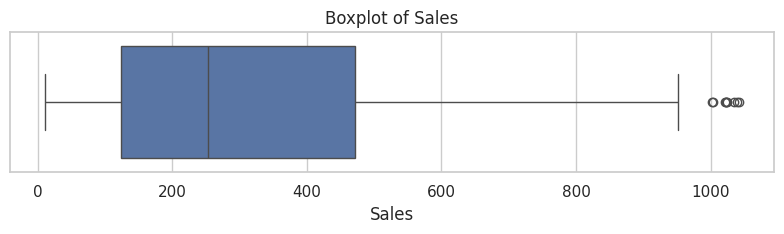

Unit price: 0 potential outliers out of 1000 non-missing values
  IQR lower bound=-34.715; upper bound=145.525


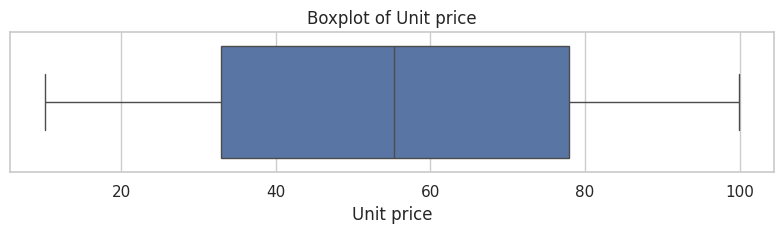

Quantity: 0 potential outliers out of 1000 non-missing values
  IQR lower bound=-4.500; upper bound=15.500


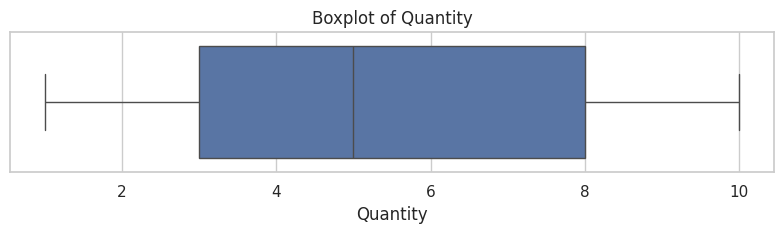

Rating: 0 potential outliers out of 1000 non-missing values
  IQR lower bound=1.000; upper bound=13.000


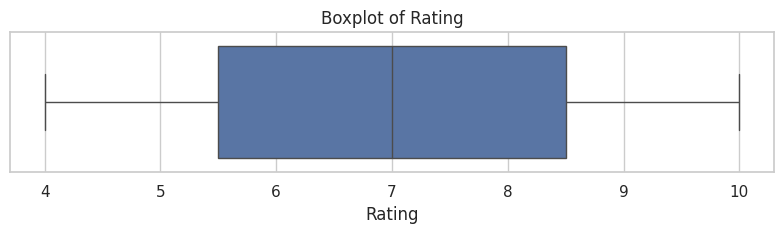

In [ ]:
for col in ["Sales", "Unit price", "Quantity", "Rating"]:
    if col in eda.columns:
        values = eda[col].dropna()
        if len(values) == 0:
            continue
        q1, q3 = values.quantile([0.25, 0.75])
        iqr = q3 - q1
        lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
        outliers = values[(values < lower) | (values > upper)]
        print(f"{col}: {len(outliers)} potential outliers out of {len(values)} non-missing values")
        print(f"  IQR lower bound={lower:.3f}; upper bound={upper:.3f}")
        plt.figure(figsize=(8, 2.5))
        sns.boxplot(x=values)
        plt.title(f"Boxplot of {col}")
        plt.tight_layout()
        plt.show()
